Статья, изменившая мир DL: [Attention Is All You Need](https://arxiv.org/pdf/1706.03762.pdf)

In [1]:
import sys, os
from google.colab import drive
import zipfile, os

drive.mount('/content/drive')


proj_root = '/content/drive/MyDrive/nas'
sys.path.append(proj_root)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Attention

## SDPA (Scaled Dot-Product Attention)

<img src="https://i2.wp.com/miro.medium.com/1*I-VlqUAk23uHVVcxbrqTHA.jpeg" alt="drawing" height="300"/>
<img src="https://data-science-blog.com/wp-content/uploads/2022/01/self_attention_map-1536x355.png" alt="drawing" height="200"/>

In [2]:
import torch
import torch.nn.functional as F
import math

In [3]:
torch.manual_seed(0)

# Q = q x k - q запросов, каждый из запросов это вектор размера k
# K = n x k - n ключей (и соответственно строчек) в таблице, каждый из ключей это вектор размера k
# V = n x m - n значений в таблице, каждое из значений это вектор размера m

q = 1
k = 2
n = 3
m = 4

Q = torch.randint(10, (q, k), dtype=torch.float32)
K = torch.randint(10, (n, k), dtype=torch.float32)
V = torch.randint(10, (n, m), dtype=torch.float32)

In [4]:
Q

tensor([[4., 9.]])

In [5]:
K

tensor([[3., 0.],
        [3., 9.],
        [7., 3.]])

In [6]:
V

tensor([[7., 3., 1., 6.],
        [6., 9., 8., 6.],
        [6., 8., 4., 3.]])

In [7]:
Q @ K.T

tensor([[12., 93., 55.]])

In [8]:
scale = math.sqrt(k)
W1 = Q @ K.T / scale
W1

tensor([[ 8.4853, 65.7609, 38.8909]])

In [9]:
W = F.softmax(W1, dim=-1)
W

tensor([[1.3351e-25, 1.0000e+00, 2.1403e-12]])

In [10]:
W @ V

tensor([[6., 9., 8., 6.]])

In [11]:
def my_SDPA(Q, K, V):
  k = K.shape[-1]
  scale = math.sqrt(k)
  W1 = Q @ K.T / scale
  W = F.softmax(W1, dim=-1)
  return W @ V, W

In [12]:
my_SDPA(Q, K, V)

(tensor([[6., 9., 8., 6.]]), tensor([[1.3351e-25, 1.0000e+00, 2.1403e-12]]))

In [13]:
F.scaled_dot_product_attention(Q, K, V)

tensor([[6., 9., 8., 6.]])

### Пример, когда запросов несколько

In [14]:
q = 6
k = 3
n = 4
m = 5

Q = torch.randint(10, (q, k), dtype=torch.float32)
K = torch.randint(10, (n, k), dtype=torch.float32)
V = torch.randint(10, (n, m), dtype=torch.float32)

In [15]:
Q

tensor([[6., 9., 1.],
        [4., 4., 1.],
        [9., 9., 9.],
        [0., 1., 2.],
        [3., 0., 5.],
        [5., 2., 9.]])

In [16]:
K

tensor([[1., 8., 8.],
        [3., 6., 9.],
        [1., 7., 3.],
        [5., 2., 1.]])

In [17]:
V

tensor([[0., 9., 3., 1., 1.],
        [0., 3., 6., 6., 7.],
        [9., 6., 3., 4., 5.],
        [0., 8., 2., 8., 2.]])

In [18]:
res, attn_weights = my_SDPA(Q, K, V)

In [19]:
res

tensor([[2.6314e-03, 8.6823e+00, 3.1584e+00, 1.2649e+00, 1.3180e+00],
        [1.7883e-02, 5.1591e+00, 4.9174e+00, 4.2021e+00, 4.8429e+00],
        [1.4296e-15, 3.0330e+00, 5.9835e+00, 5.9725e+00, 6.9670e+00],
        [7.8468e-03, 6.0000e+00, 4.4987e+00, 3.5005e+00, 4.0009e+00],
        [8.4498e-09, 3.0105e+00, 5.9948e+00, 5.9913e+00, 6.9895e+00],
        [2.5603e-15, 3.0010e+00, 5.9995e+00, 5.9991e+00, 6.9990e+00]])

In [20]:
F.scaled_dot_product_attention(Q, K, V)

tensor([[2.6314e-03, 8.6823e+00, 3.1584e+00, 1.2649e+00, 1.3180e+00],
        [1.7883e-02, 5.1591e+00, 4.9174e+00, 4.2021e+00, 4.8429e+00],
        [1.4296e-15, 3.0330e+00, 5.9835e+00, 5.9725e+00, 6.9670e+00],
        [7.8468e-03, 6.0000e+00, 4.4987e+00, 3.5005e+00, 4.0009e+00],
        [8.4498e-09, 3.0105e+00, 5.9948e+00, 5.9913e+00, 6.9895e+00],
        [2.5603e-15, 3.0010e+00, 5.9995e+00, 5.9991e+00, 6.9990e+00]])

#### Визулизация attn_weights

In [21]:
attn_weights

tensor([[9.4691e-01, 5.2797e-02, 2.9238e-04, 4.9995e-10],
        [3.5881e-01, 6.3915e-01, 1.9870e-03, 6.2196e-05],
        [5.5073e-03, 9.9449e-01, 1.5885e-16, 2.6977e-23],
        [4.9956e-01, 4.9956e-01, 8.7186e-04, 4.8282e-06],
        [1.7422e-03, 9.9826e-01, 9.3886e-10, 2.9791e-09],
        [1.7331e-04, 9.9983e-01, 2.8447e-16, 2.8062e-18]])

In [22]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_attention_weights(attn_weights):
    attn_weights = np.array(attn_weights)

    plt.figure(figsize=(8, 5))
    plt.imshow(attn_weights, cmap='gray', interpolation='nearest')

    plt.colorbar()

    plt.title('Вектора внимания для каждого из запросов')

    plt.show()

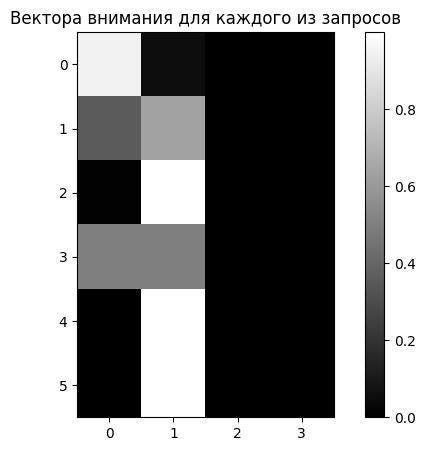

In [23]:
visualize_attention_weights(attn_weights)

## MHA (Multi-Head Attention)

<img src="https://aiml.com/wp-content/uploads/2023/09/Self-Attention-vs-Multi-headed-Attention.png" alt="drawing" height="400"/>

In [24]:
import torch
import math

def my_SDPA(Q, K, V, scale=None):
    scale = math.sqrt(K.shape[-1]) if scale is None else scale
    W1 = Q @ K.transpose(-2, -1) / scale
    W = F.softmax(W1, dim=-1)
    return W @ V, W

class MyMHA(torch.nn.Module):
    def __init__(self, embed_dim, num_heads, bias=False):
        # embed_dim = 768
        # num_heads = 8 (each token of size 96)

        super().__init__()
        self.bias = bias

        self.in_proj_weight = torch.nn.Parameter(torch.empty((3 * embed_dim, embed_dim)))
        torch.nn.init.xavier_uniform_(self.in_proj_weight)

        self.in_proj_bias = torch.nn.Parameter(torch.zeros(3 * embed_dim), requires_grad=bias)

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        assert self.head_dim * num_heads == self.embed_dim, "embed_dim must be divisible by num_heads"

        self.scale = math.sqrt(self.head_dim)

        self.out_proj = torch.nn.Linear(embed_dim, embed_dim, bias=bias)

    def forward(self, q, k, v, average_attn_weights=False):
        packed_in_proj_w = self.in_proj_weight.chunk(3) # 3 x embed_dim x embed_dim
        packed_in_proj_b = self.in_proj_bias.chunk(3) # 3 x embed_dim

        bs, N_len, E = q.shape
        qkv_in_projected = list(map(lambda x: x[0] @ x[1].T + x[2],
                        zip([q, k, v], packed_in_proj_w, packed_in_proj_b)))
        # q.shape = bs x N x embed_dim
        q, k, v = list(map(lambda x:
                           x.view(bs, N_len, self.num_heads, self.head_dim).transpose(-3, -2),
                           qkv_in_projected))
        # q.shape = bs x num_heads x N x head_dim
        out1, attn_output_weights = my_SDPA(q, k, v, self.scale)
        # out1.shape = bs x num_heads x N x head_dim
        out2 = out1.transpose(-3, -2).reshape(bs, N_len, -1)
        # out2.shape = bs x N x embed_dim
        out3 = self.out_proj(out2)
        if average_attn_weights:
            attn_output_weights = attn_output_weights.mean(dim=1)
        return out3, attn_output_weights

In [25]:
bs, N_len, embed_dim = in_shape = (3, 7, 512)

q = torch.randn(in_shape)
k = torch.randn(in_shape)
v = torch.randn(in_shape)

num_heads = 4
bias = False
average_attn_weights = False

torch_MHA = torch.nn.MultiheadAttention(embed_dim, num_heads,
                                        batch_first=True, bias=bias)
my_MHA = MyMHA(embed_dim, num_heads, bias=bias)

my_MHA.in_proj_weight.data = torch_MHA.in_proj_weight.data
my_MHA.out_proj.weight.data = torch_MHA.out_proj.weight.data
if bias:
    my_MHA.in_proj_bias.data = torch_MHA.in_proj_bias.data
    my_MHA.out_proj.bias.data = torch_MHA.out_proj.bias.data

In [26]:
torch_attn_output, torch_attn_weights = torch_MHA(q, k, v,
                                                  average_attn_weights=average_attn_weights)
my_attn_output, my_attn_weights = my_MHA(q, k, v,
                                         average_attn_weights=average_attn_weights)

assert torch.nn.functional.mse_loss(torch_attn_output, my_attn_output) < 0.000001, \
            "---- Forward attn_output: test failed :("
print("++++ Forward attn_output: test passed!")

assert torch.nn.functional.mse_loss(torch_attn_weights, my_attn_weights) < 0.000001, \
    "---- Forward attn_weights: test failed :("
print("++++ Forward attn_weights: test passed!")

++++ Forward attn_output: test passed!
++++ Forward attn_weights: test passed!


In [27]:
torch_attn_output.shape

torch.Size([3, 7, 512])

# ViT (Vision Transformer)

Paper: https://arxiv.org/pdf/2010.11929.pdf

ViT from scratch: https://github.com/lucidrains/vit-pytorch/blob/main/vit_pytorch/vit.py

<img src="https://i.postimg.cc/907rsLzj/vit-arch.png" alt="drawing" height="500"/>

In [28]:
import torchvision
from torchvision import transforms as T

In [29]:
from PIL import Image
import requests
from io import BytesIO

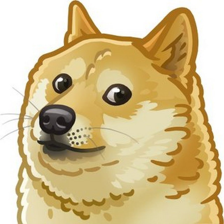

In [31]:
url = 'https://i.postimg.cc/s2DDgbds/image.png'
response = requests.get(url)
pil_img = Image.open(BytesIO(response.content)).convert('RGB').resize((224, 224))
pil_img

In [32]:
patch_size = 16
patch_stride = 16
x = T.ToTensor()(pil_img)[None, :]
x = x.permute((0, 2, 3, 1))
patches = x.unfold(1, patch_size, patch_stride).unfold(2, patch_size, patch_stride)
patches.shape

torch.Size([1, 14, 14, 3, 16, 16])

In [33]:
# 224x224x3 ->

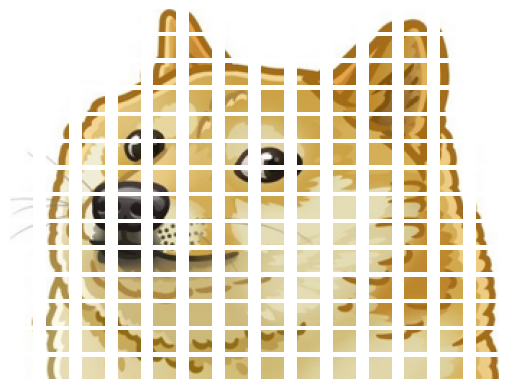

In [34]:
import matplotlib.pyplot as plt

images = patches[0]

fig, axes = plt.subplots(len(images), len(images[0]))

for i in range(len(images)):
    for j in range(len(images[i])):
        np_image = images[i][j].numpy()
        transposed_image = np_image.transpose(1, 2, 0)
        axes[i, j].imshow(transposed_image)
        axes[i, j].axis('off')
""
plt.show()

In [35]:
def img_to_patches(img, patch_size=16, patch_stride=16):
    batch_size, C, W, H = img.shape
    img = img.permute((0, 2, 3, 1))
    patches = img.unfold(1, patch_size, patch_stride).unfold(2, patch_size, patch_stride)
    patches = patches.reshape((batch_size, (W // patch_size) * (H // patch_stride), -1))
    return patches

In [36]:
import torch
from torch import nn, optim

class ViT_Encoder_Block(nn.Module):
    def __init__(self, d_model, num_heads):
        super(ViT_Encoder_Block, self).__init__()
        self.heads = num_heads
        self.layer_norm = nn.LayerNorm(d_model)

        self.MHA = nn.MultiheadAttention(d_model, num_heads=num_heads, batch_first=True)

        self.out_layers = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, d_model * 4),
            nn.GELU(),
            nn.Linear(d_model * 4, d_model),
        )

    def forward(self, x):
        # x.shape = bs x 197 x d_model
        out1 = self.layer_norm(x)

        attn_output, _ = self.MHA(out1, out1, out1)

        out2 = attn_output + x
        out3 = self.out_layers(out2)
        return out3 + out2


class ViT_Classifier(nn.Module):
    def __init__(self, num_classes, channels=3, img_width=224, img_height=224,
                 patch_size=16, patch_stride=16,
                 d_model=768, num_layers=8, num_heads=12):
        super(ViT_Classifier, self).__init__()
        self.channels = channels
        self.img_width = img_width
        self.img_height = img_height
        self.patch_size = patch_size
        self.patch_stride = patch_stride
        self.cls_token = nn.Parameter(torch.randn(d_model))
        self.PEs = nn.Parameter(torch.randn(197, d_model))
        self.fc = nn.Linear(channels * patch_size * patch_stride, d_model)
        self.layers = nn.Sequential(*[ViT_Encoder_Block(d_model, num_heads) for _ in range(num_layers)])
        self.end_FC = nn.Linear(d_model, num_classes)

    def forward(self, img):
        # img.shape = bs x 3 x 224 x 224
        x = img_to_patches(img, self.patch_size, self.patch_stride)
        # x.shape = bs x 196 x 768
        x = self.fc(x)
        # x.shape = bs x 196 x d_model
        batch_sz = img.shape[0]
        token = self.cls_token.repeat(batch_sz, 1, 1)
        x_embed = torch.cat((token, x), dim=1)
        # x_embed.shape = bs x 197 x d_model
        x_embed_pos = x_embed + self.PEs
        out = self.layers(x_embed_pos)
        out = self.end_FC(out[:, 0])
        return out

## Скачиваем датасет из Kaggle

In [37]:
!pip install -q kaggle

In [38]:
import os
kaggle_token = {"username":"izhanvarsky", "key":"e06d966b7ebc01cb2eaeec716e2d1cf0"}

os.environ['KAGGLE_USERNAME'] = kaggle_token['username']
os.environ['KAGGLE_KEY'] = kaggle_token['key']

In [39]:
# https://www.kaggle.com/datasets/shaunthesheep/microsoft-catsvsdogs-dataset
!kaggle datasets download -d shaunthesheep/microsoft-catsvsdogs-dataset --force

Dataset URL: https://www.kaggle.com/datasets/shaunthesheep/microsoft-catsvsdogs-dataset
License(s): other
 98% 772M/788M [00:06<00:00, 94.1MB/s]
100% 788M/788M [00:07<00:00, 117MB/s] 


In [40]:
!unzip -q microsoft-catsvsdogs-dataset.zip

replace MSR-LA - 3467.docx? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


In [41]:
# https://stackoverflow.com/questions/63425209/cannot-identify-image-file-while-trying-to-use-tensorflow-on-google-collab

from PIL import Image, ImageFile
from tqdm import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True

def validate_images(folder_path):
    for root, dirs, files in os.walk(folder_path):
        print(f"Cur dir: {root}")
        for file in tqdm(files):
            if file.lower().endswith(('.jpg', '.jpeg', '.png')):
                image_path = os.path.join(root, file)
                try:
                  img = Image.open(image_path)
                  img.load()
                  img.close()
                except Exception as e:
                  print(f"Image is incorrect: {image_path}")
                  print(e)
                  os.remove(image_path)

In [42]:
validate_images('./PetImages')

!rm "./PetImages/Dog/9057.jpg"
!rm "./PetImages/Dog/11702.jpg"
!rm "./PetImages/Cat/666.jpg"

Cur dir: ./PetImages


100%|██████████| 2/2 [00:00<00:00, 6842.26it/s]


Cur dir: ./PetImages/Cat


 89%|████████▉ | 11126/12501 [00:11<00:02, 643.95it/s]

Image is incorrect: ./PetImages/Cat/666.jpg
cannot identify image file './PetImages/Cat/666.jpg'


100%|██████████| 12501/12501 [00:13<00:00, 951.68it/s]


Cur dir: ./PetImages/Dog


 43%|████▎     | 5369/12501 [00:05<00:07, 1000.42it/s]

Image is incorrect: ./PetImages/Dog/11702.jpg
cannot identify image file './PetImages/Dog/11702.jpg'


 66%|██████▌   | 8229/12501 [00:08<00:04, 942.59it/s]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 12501/12501 [00:13<00:00, 910.46it/s]


rm: cannot remove './PetImages/Dog/11702.jpg': No such file or directory
rm: cannot remove './PetImages/Cat/666.jpg': No such file or directory


In [43]:
from tqdm import tqdm
import random

def split_dataset(dataset_root, test_ratio=0.05):
    out_train_fname = 'train.csv'
    out_test_fname = 'test.csv'
    print("Running splitting dataset to Train and Test")
    print(f"test_ratio: {test_ratio}")
    print(f"dataset_root: {dataset_root}")
    print(f"out_train_fname: {out_train_fname}")
    print(f"out_test_fname: {out_test_fname}")

    classes = os.listdir(dataset_root)
    out_train_files = []
    out_test_files = []
    for cls in tqdm(classes):
        cur_dir = f'{dataset_root}/{cls}'
        if not os.path.isdir(cur_dir):
            continue
        img_names = [fname for fname in os.listdir(cur_dir)
                     if fname.lower().endswith(('.jpg', '.jpeg', '.png'))]
        test_size = int(len(img_names) * test_ratio)
        test_files = random.sample(img_names, test_size)
        for img_name in img_names:
            p = f'{cls},{img_name}\n'
            if img_name in test_files:
                out_test_files.append(p)
            else:
                out_train_files.append(p)
    with open(f'{dataset_root}/{out_train_fname}', 'w') as f:
        f.writelines(out_train_files)
    print(f'Number of train images: {len(out_train_files)}')
    with open(f'{dataset_root}/{out_test_fname}', 'w') as f:
        f.writelines(out_test_files)
    print(f'Number of test images: {len(out_test_files)}')

In [44]:
dataset_root = './PetImages'
split_dataset(dataset_root, 0.1)

Running splitting dataset to Train and Test
test_ratio: 0.1
dataset_root: ./PetImages
out_train_fname: train.csv
out_test_fname: test.csv


100%|██████████| 4/4 [00:00<00:00,  9.70it/s]

Number of train images: 22499
Number of test images: 2498


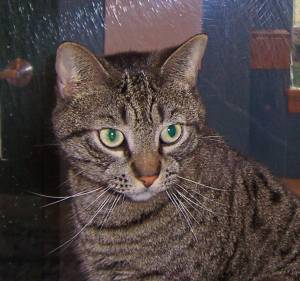

In [45]:
Image.open(f'{dataset_root}/Cat/1.jpg')

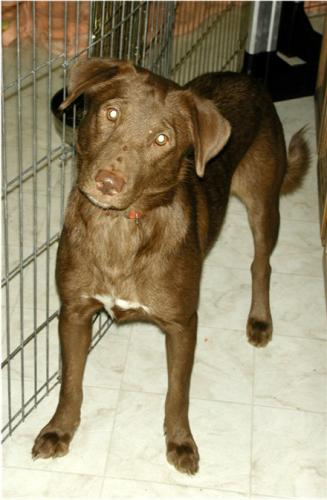

In [46]:
Image.open(f'{dataset_root}/Dog/1.jpg')

## Аугментации

In [47]:
from torchvision import transforms as T
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [48]:
img_sz = 224

normalize = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

train_data_transforms = T.Compose([
        T.Resize((img_sz, img_sz)),
        T.RandomHorizontalFlip(),
        # T.RandomRotation(degrees=30),
        # T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
        T.ToTensor(),
        normalize
    ])
test_data_transforms = T.Compose([
    T.Resize((img_sz, img_sz)),
    T.ToTensor(),
    normalize
])

## ImageDatasets

In [49]:
from torch.utils.data import Dataset
from PIL import Image
import pandas as pd

class ImageDataset(Dataset):
    def __init__(self, dataset_root, csv_filename, transform):
        print("Reading Image Dataset...")
        self.dataset_root = dataset_root
        self.classes = sorted([name for name in os.listdir(self.dataset_root)
                               if os.path.isdir(f'{self.dataset_root}/{name}')])
        self.label_to_idx = {val: idx for idx, val in enumerate(self.classes)}

        print("Reading dataset file paths...")
        self.img_labels = pd.read_csv(f'{dataset_root}/{csv_filename}', delimiter=',')
        self.transform = transform
        print("Image Dataset instance created!")

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, index):
        label = self.img_labels.iloc[index, 0]
        img_name = self.img_labels.iloc[index, 1]
        img_path = f'{self.dataset_root}/{label}/{img_name}'
        image = Image.open(img_path).convert('RGB')

        image_tensor = self.transform(image)
        image.close()
        return image_tensor, self.label_to_idx[label]

In [50]:
image_datasets = dict()
image_datasets['train'] = ImageDataset(dataset_root=dataset_root,
                                       csv_filename='train.csv',
                                       transform=train_data_transforms)
image_datasets['test'] = ImageDataset(dataset_root=dataset_root,
                                       csv_filename='test.csv',
                                       transform=test_data_transforms)

Reading Image Dataset...
Reading dataset file paths...
Image Dataset instance created!
Reading Image Dataset...
Reading dataset file paths...
Image Dataset instance created!


## Dataloaders

In [51]:
from torch.utils.data import DataLoader

batch_size = 32
num_workers = 2

dataloaders = dict()
dataloaders['train'] = DataLoader(image_datasets['train'],
                                  batch_size=batch_size,
                                  shuffle=True,
                                  num_workers=num_workers,
                                  pin_memory=True,
                                  drop_last=True)
dataloaders['test'] = DataLoader(image_datasets['test'],
                                  batch_size=batch_size,
                                  shuffle=False,
                                  num_workers=num_workers,
                                  pin_memory=True)

## Training

In [52]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [53]:
model = ViT_Classifier(num_classes=2, channels=3, num_layers=4, num_heads=8).to(device)

In [54]:
!pip install torchsummary

In [55]:
from torchsummary import summary

summary(model, input_size=(3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1             [-1, 196, 768]         590,592
         LayerNorm-2             [-1, 197, 768]           1,536
MultiheadAttention-3  [[-1, 197, 768], [-1, 197, 197]]               0
         LayerNorm-4             [-1, 197, 768]           1,536
            Linear-5            [-1, 197, 3072]       2,362,368
              GELU-6            [-1, 197, 3072]               0
            Linear-7             [-1, 197, 768]       2,360,064
 ViT_Encoder_Block-8             [-1, 197, 768]               0
         LayerNorm-9             [-1, 197, 768]           1,536
MultiheadAttention-10  [[-1, 197, 768], [-1, 197, 197]]               0
        LayerNorm-11             [-1, 197, 768]           1,536
           Linear-12            [-1, 197, 3072]       2,362,368
             GELU-13            [-1, 197, 3072]               0
           Linear-14    

In [56]:
import torch.optim as optim

learning_rate = 1e-5

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [57]:
from sklearn import metrics

def run_epoch(phase, dataloader):
  if phase == 'train':
      model.train()
  else:
      model.eval()

  running_loss = 0.0
  running_corrects = 0
  y_test = []
  y_pred = []
  all_elems_count = 0
  cur_tqdm = tqdm(dataloader)
  for inputs, labels in cur_tqdm:
      bz = inputs.shape[0]
      all_elems_count += bz

      inputs = inputs.to(device, non_blocking=True)
      labels = labels.to(device, non_blocking=True)

      outputs = model(inputs)
      loss = criterion(outputs, labels)

      if phase == 'train':
          optimizer.zero_grad()
          loss.backward()
          optimizer.step()

      _, preds = torch.max(outputs, 1)
      y_test.extend(labels.detach().cpu().numpy())
      y_pred.extend(preds.detach().cpu().numpy())
      running_loss += loss.item() * bz
      corrects_cnt = torch.sum(preds == labels.detach())
      running_corrects += corrects_cnt
      show_dict = {'Loss': f'{loss.item():.6f}',
                    'Corrects': f'{corrects_cnt.item()}/{bz}',
                    'Accuracy': f'{(corrects_cnt * 100 / bz).item():.3f}%'}
      cur_tqdm.set_postfix(show_dict)

  conf_matrix = metrics.confusion_matrix(y_test, y_pred)

  print("Calculating metrics...")
  f05_macro = metrics.fbeta_score(y_test, y_pred, average="macro", beta=0.5)
  f1_macro = metrics.f1_score(y_test, y_pred, average="macro")
  epoch_loss = running_loss / all_elems_count
  epoch_acc = running_corrects.float().item() / all_elems_count
  return epoch_loss, epoch_acc, f05_macro, f1_macro, conf_matrix

def test_epoch(dataloader):
    with torch.inference_mode():
      return run_epoch('test', dataloader)

def train_epoch(dataloader):
    return run_epoch('train', dataloader)

In [58]:
import time
import math
import os

log_folder = 'logs'
os.makedirs(log_folder, exist_ok=True)

def train_model(dataloaders, num_epochs=5):
  print(f"Training model with params:")
  print(f"Optim: {optimizer}")
  print(f"Criterion: {criterion}")

  phases = ['train', 'test']
  for phase in dataloaders:
      if phase not in phases:
          phases.append(phase)

  saved_epoch_losses = {phase: [] for phase in phases}
  saved_epoch_accuracies = {phase: [] for phase in phases}
  saved_epoch_f1_macros = {phase: [] for phase in phases}

  for epoch in range(1, num_epochs + 1):
      start_time = time.time()

      print("=" * 100)
      print(f'Epoch {epoch}/{num_epochs}')
      print('-' * 10)

      for phase in phases:
          print("--- Cur phase:", phase)
          epoch_loss, epoch_acc, f05_macro, f1_macro, conf_matrix = \
              train_epoch(dataloaders[phase]) if phase == 'train' \
                  else test_epoch(dataloaders[phase])
          saved_epoch_losses[phase].append(epoch_loss)
          saved_epoch_accuracies[phase].append(epoch_acc)
          saved_epoch_f1_macros[phase].append(f1_macro)
          print(f'{phase} loss: {epoch_loss:.6f}, '
                f'acc: {epoch_acc:.6f}, '
                f'f05_macro: {f05_macro:.6f}, '
                f'f1_macro: {f1_macro:.6f}')
          print("Confusion matrix:")
          print(conf_matrix)

      model.eval()
      if epoch > 1:
        plt.title(f'Losses during training. Epoch {epoch}/{num_epochs}.')
        plt.plot(range(1, epoch + 1), saved_epoch_losses['train'], label='Train Loss')
        plt.plot(range(1, epoch + 1), saved_epoch_losses['test'], label='Test Loss')
        plt.xlabel('Epochs')
        plt.ylabel(criterion.__class__.__name__)
        plt.legend(loc="upper left")
        plt.savefig(f'{log_folder}/loss_graph_epoch{epoch + 1}.png')
        plt.show()
        plt.close('all')

        plt.title(f'Accuracies during training. Epoch {epoch}/{num_epochs}.')
        plt.plot(range(1, epoch + 1), saved_epoch_accuracies['train'], label='Train Acc')
        plt.plot(range(1, epoch + 1), saved_epoch_accuracies['test'], label='Test Acc')
        plt.xlabel('Epochs')
        plt.ylabel('Accuracy')
        plt.legend(loc="upper left")
        plt.savefig(f'{log_folder}/acc_graph_epoch{epoch + 1}.png')
        plt.show()
        plt.close('all')

      end_time = time.time()
      epoch_time = end_time - start_time
      print("-" * 10)
      print(f"Epoch Time: {math.floor(epoch_time // 60)}:{math.floor(epoch_time % 60):02d}")

  print("*** Training Completed ***")

  return saved_epoch_losses, saved_epoch_accuracies, saved_epoch_f1_macros

In [59]:
# num_epochs = 10

# train_model(dataloaders, num_epochs)

## ViT with nn.TransformerEncoder

In [60]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ViT_torch(nn.Module):
    def __init__(self, num_classes, channels=3, img_size=224, patch_size=16,
                 dim=768,
                 num_layers=12, num_heads=12, mlp_dim=3072, dropout=0.1):
        super(ViT_torch, self).__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2

        # Другой вариант как разбить изображение на патчи нужной размерности
        self.patch_embeddings = nn.Conv2d(in_channels=channels, out_channels=dim,
                                          kernel_size=patch_size, stride=patch_size)

        self.class_token = nn.Parameter(torch.zeros(1, 1, dim))

        self.position_embeddings = nn.Parameter(torch.zeros(1, self.num_patches + 1, dim))

        encoder_layer = nn.TransformerEncoderLayer(d_model=dim, nhead=num_heads,
                                                    dim_feedforward=mlp_dim,
                                                    dropout=dropout,
                                                    batch_first=True,
                                                    activation="gelu",
                                                    #norm_first=True,
                                                    )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        self.fc = nn.Linear(dim, num_classes)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.patch_embeddings(x)
        # x.shape == bs x 768 x 14 x 14
        x = x.flatten(2)
        # x.shape == bs x 768 x 196
        x = x.transpose(1, 2)
        # x.shape == bs x 196 x 768

        batch_size = x.size(0)
        class_tokens = self.class_token.expand(batch_size, -1, -1)  # bs x 1 x 768
        x = torch.cat((class_tokens, x), dim=1)
        # x.shape == bs x 197 x 768

        x += self.position_embeddings
        # x.shape == bs x 197 x 768

        x = self.transformer_encoder(x)
        # x.shape == bs x 197 x 768

        x = x[:, 0]
        # x.shape == bs x 768

        x = self.dropout(x)
        x = self.fc(x)
        # x.shape == bs x num_classes
        return x

In [61]:
# Пример использования
model = ViT_torch(num_classes=2, channels=3, num_layers=4, num_heads=8).to(device)
input_tensor = torch.randn(1, 3, 224, 224).to(device)  # Пример входного тензора
output = model(input_tensor)
print(output.shape)  # Ожидаемый вывод: torch.Size([1, 2])

torch.Size([1, 2])


In [62]:
# import torch.optim as optim

# learning_rate = 1e-5

# criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# num_epochs = 10

# train_model(dataloaders, num_epochs)

In [63]:
# train_model(dataloaders, num_epochs)

In [64]:
%pwd

'/content'

In [65]:
%cd /content/drive/MyDrive/nas

!pip install -e .


/content/drive/MyDrive/nas
Obtaining file:///content/drive/MyDrive/nas
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for ssonn (pyproject.toml) ... done
  Created wheel for ssonn: filename=ssonn-1.0.0-0.editable-py3-none-any.whl size=5617 sha256=936fe14b3bc3019032890f3ea30e1124c734a2c4f40c30cfd943e1a78b7ccb64
  Stored in directory: /tmp/pip-ephem-wheel-cache-qbu5k5ae/wheels/4e/59/51/45a96530856cec6c7e8b21d5ad303c8350aa44f794b4fa3fee
Successfully built ssonn
  Attempting uninstall: ssonn
    Found existing installation: ssonn 1.0.0
    Uninstalling ssonn-1.0.0:
      Successfully uninstalled ssonn-1.0.0


In [66]:
import torch
import torch.nn as nn
import torch.optim as optim

from ssonn.model.utils import *
from ssonn.metrics.nonlinearity_metrics import *
from ssonn.metrics.edge_finder import *
from ssonn.metrics.train_metrics import *
from ssonn.train.train import *


In [67]:
%cd /content

/content


In [68]:

class SimpleFCN(nn.Module):
    def __init__(self, input_size, output_size):
        super(SimpleFCN, self).__init__()
        self.fc0 = nn.Linear(input_size, output_size)

    def forward(self, x):
        # x: [B, N, input_size]
        return self.fc0(x)

class SimpleFCN(nn.Module):
    def __init__(self, input_size, output_size):
        super(SimpleFCN, self).__init__()
        self.fc0 = nn.Linear(input_size, output_size)

    def forward(self, x):
        # x: [B, N, input_size]  или [B*N, input_size]
        if x.dim() == 3:
            B, N, D = x.shape
            x = x.reshape(B * N, D)      # [B*N, D]
            x = self.fc0(x)              # [B*N, 3D]
            x = x.reshape(B, N, -1)      # [B, N, 3D]
            return x
        else:
            return self.fc0(x)



In [ ]:
def convert_dense_to_sparse_network(
    model: nn.Module, layers, device="cpu"
) -> nn.Module:
    """
    Converts dense layers in a model to sparse equivalents.
    """
    new_model = deepcopy(model)
    
    # Используем named_modules() для поиска вложенных слоёв
    for name, module in model.named_modules():
        if module in layers:
            # Получаем путь к модулю (например, "fc0" или "qkv_module.fc0")
            sparse_weight = dense_to_sparse(module.weight.data, device=device)
            sparse_bias = dense_to_sparse(module.bias.data, device=device)
            
            # Заменяем модуль в new_model по пути name
            parts = name.split('.')
            parent = new_model
            for part in parts[:-1]:
                parent = getattr(parent, part)
            setattr(parent, parts[-1], ExpandingLinear(sparse_weight, sparse_bias, device=device))
    
    return new_model

In [69]:
def make_sparse_qkv_module(d_model, device):
    dense_qkv = SimpleFCN(input_size=d_model, output_size=3 * d_model)
    sparse_qkv = convert_dense_to_sparse_network(
        dense_qkv, layers=[dense_qkv.fc0], device=device
    )
    return sparse_qkv.to(device)


In [70]:
class CustomMHA(nn.Module):
    def __init__(self, d_model, num_heads, qkv_module, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        self.qkv_module = qkv_module          # sparse QKV: [B,N,d] -> [B,N,3d]
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        B, N, _ = x.shape

        qkv = self.qkv_module(x)                        # [B, N, 3d]
        qkv = qkv.view(B, N, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)                # [3, B, H, N, Hd]
        q, k, v = qkv[0], qkv[1], qkv[2]

        scores = torch.matmul(q, k.transpose(-2, -1)) / (self.head_dim ** 0.5)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))
        attn = torch.softmax(scores, dim=-1)
        attn = self.dropout(attn)

        out = torch.matmul(attn, v)                     # [B, H, N, Hd]
        out = out.transpose(1, 2).contiguous().view(B, N, self.d_model)
        out = self.out_proj(out)
        return out


In [71]:
class ViTEncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, qkv_module, mlp_ratio=4.0, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn = CustomMHA(d_model, num_heads, qkv_module, dropout=dropout)
        self.norm2 = nn.LayerNorm(d_model)
        hidden = int(d_model * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x, mask=None):
        h = self.norm1(x)
        x = x + self.attn(h, mask)
        h = self.norm2(x)
        x = x + self.mlp(h)
        return x


In [72]:

class SparseViT(nn.Module):
    def __init__(
        self,
        num_classes,
        img_size=224,
        patch_size=16,
        dim=768,
        depth=4,
        num_heads=8,
        channels=3,
        dropout=0.1,
        device="cpu",
    ):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2
        self.dim = dim

        self.patch_embeddings = nn.Conv2d(
            in_channels=channels,
            out_channels=dim,
            kernel_size=patch_size,
            stride=patch_size,
        )

        self.class_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.position_embeddings = nn.Parameter(
            torch.zeros(1, self.num_patches + 1, dim)
        )

        self.encoder_blocks = nn.ModuleList()
        for i in range(depth):
            qkv_sparse = make_sparse_qkv_module(dim, device)
            setattr(self, f"qkv_layer_{i}", qkv_sparse)   # важно для sparse‑логики
            block = ViTEncoderBlock(dim, num_heads, qkv_sparse, dropout=dropout)
            self.encoder_blocks.append(block)

        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(dim, num_classes)

    def forward(self, x, mask=None):
        x = self.patch_embeddings(x)                  # [B, d, H', W']
        x = x.flatten(2).transpose(1, 2)              # [B, N, d]

        B = x.size(0)
        cls = self.class_token.expand(B, 1, -1)
        x = torch.cat([cls, x], dim=1)
        x = x + self.position_embeddings

        for block in self.encoder_blocks:
            x = block(x, mask)

        x = x[:, 0]
        x = self.dropout(x)
        return self.head(x)


In [73]:
def apply_sparse_growth_and_prune(
    model,
    optimizer,
    edge_finder,
    hyperparams,
    epoch,
    val_losses,
    replace_epoch,
    non_zero_masks,
    logs,
    experiment=None,
):
    # --- расширение по плато ---
    if len(val_losses) < hyperparams["plateau_window_size"]:
        return

    if epoch - replace_epoch[-1] > max(
        hyperparams["prune_after_epochs"],
        hyperparams["min_epochs_between_expansions"],
        hyperparams["plateau_window_size"],
    ):
        print("Проверка условия расширения...")
        recent_changes = [
            abs(val_losses[i] - val_losses[i - 1])
            for i in range(-hyperparams["plateau_window_size"], 0)
        ]
        avg_change = sum(recent_changes) / hyperparams["plateau_window_size"]

        print(f"Среднее изменение loss: {avg_change}, порог: {hyperparams['plateau_threshold']}")

        if avg_change < hyperparams["plateau_threshold"]:
            print("Условие плато выполнено, начинаем расширение...")
            len_choose = 0
            for layer_name in hyperparams["expansion_thresholds"].keys():
                print(f"Обработка слоя: {layer_name}")
                layer = getattr(model, layer_name)   # qkv_layer_i - это SimpleFCN

                # ИСПРАВЛЕНИЕ: если это SimpleFCN, получаем ExpandingLinear из fc0
                from ssonn.model.model import ExpandingLinear
                if hasattr(layer, 'fc0') and isinstance(layer.fc0, ExpandingLinear):
                    expanding_layer = layer.fc0
                elif isinstance(layer, ExpandingLinear):
                    expanding_layer = layer
                else:
                    print(f"ОШИБКА: слой {layer_name} не содержит ExpandingLinear")
                    print(f"Тип слоя: {type(layer)}")
                    if hasattr(layer, 'fc0'):
                        print(f"Тип fc0: {type(layer.fc0)}")
                    continue

                print(f"Найден ExpandingLinear для слоя {layer_name}")
                len_choose += edge_replacement_func_new_layer(
                    model,
                    expanding_layer,  # Передаём ExpandingLinear, а не SimpleFCN
                    optimizer,
                    hyperparams["expansion_thresholds"][layer_name],
                    edge_finder,
                    experiment,
                    hyperparams["start_fully_connected"],
                )
                non_zero_masks[layer_name] = expanding_layer.get_non_zero_params()
            replace_epoch.append(epoch)
            logs["len_choose"] = len_choose
            print(f"Расширение завершено, добавлено рёбер: {len_choose}")

    # --- прюнинг спустя prune_after_epochs после расширения ---
    if (
        epoch - replace_epoch[-1] == hyperparams["prune_after_epochs"]
        and replace_epoch[-1] != 0
    ):
        print("Начинаем прюнинг...")
        len_choose = 0
        for layer_name in hyperparams["pruning_thresholds"].keys():
            layer = getattr(model, layer_name)

            # ИСПРАВЛЕНИЕ: аналогично для прюнинга
            from ssonn.model.model import ExpandingLinear
            if hasattr(layer, 'fc0') and isinstance(layer.fc0, ExpandingLinear):
                expanding_layer = layer.fc0
            elif isinstance(layer, ExpandingLinear):
                expanding_layer = layer
            else:
                print(f"ОШИБКА: слой {layer_name} не содержит ExpandingLinear")
                continue

            len_choose += edge_deletion_func_new_layer(
                model,
                expanding_layer,  # Передаём ExpandingLinear
                optimizer,
                non_zero_masks[layer_name],
                hyperparams["pruning_thresholds"][layer_name],
                edge_finder,
            )
        logs["del_len_choose"] = len_choose
        print(f"Прюнинг завершён, удалено рёбер: {len_choose}")

In [ ]:
def train_vit_sparse(
    model,
    dataloaders,
    criterion,
    optimizer,
    hyperparams,
    device,
    num_epochs=5,
    experiment=None,
):
    model = model.to(device)

    # валидатор для EdgeFinder – возьмём 'test', если нет отдельного 'val'
    val_loader_for_edges = dataloaders.get("val", dataloaders["train"])

    edge_finder = EdgeFinder(
        hyperparams["edge_importance_metric"],
        val_loader_for_edges,
        device=device,
        aggregation_mode=hyperparams["edge_score_aggregation"],
        max_to_replace=hyperparams["max_new_edges_per_expansion"],
    )

    phases = ['train', 'test']
    if "val" in dataloaders and "val" not in phases:
        phases.append("val")

    saved_epoch_losses = {p: [] for p in phases}
    saved_epoch_accuracies = {p: [] for p in phases}
    saved_epoch_f1_macros = {p: [] for p in phases}

    val_losses = []
    non_zero_masks = {}
    replace_epoch = [0]

    for epoch in range(1, num_epochs + 1):
        print("=" * 100)
        print(f'Epoch {epoch}/{num_epochs}')
        print('-' * 10)

        epoch_logs = {}

        for phase in phases:
            print("--- Cur phase:", phase)
            if phase == 'train':
                ep_loss, ep_acc, f05_macro, f1_macro, conf_matrix = \
                    train_epoch(dataloaders[phase])
            else:
                ep_loss, ep_acc, f05_macro, f1_macro, conf_matrix = \
                    test_epoch(dataloaders[phase])

            saved_epoch_losses[phase].append(ep_loss)
            saved_epoch_accuracies[phase].append(ep_acc)
            saved_epoch_f1_macros[phase].append(f1_macro)

            print(f'{phase} loss: {ep_loss:.6f}, '
                  f'acc: {ep_acc:.6f}, '
                  f'f05_macro: {f05_macro:.6f}, '
                  f'f1_macro: {f1_macro:.6f}')
            print("Confusion matrix:")
            print(conf_matrix)

            if phase in ('test', 'val'):
                val_losses.append(ep_loss)

        # sparse‑логика после завершения всех фаз эпохи
        if len(val_losses) >= hyperparams["plateau_window_size"]:
            apply_sparse_growth_and_prune(
                model=model,
                optimizer=optimizer,
                edge_finder=edge_finder,
                hyperparams=hyperparams,
                epoch=epoch,
                val_losses=val_losses,
                replace_epoch=replace_epoch,
                non_zero_masks=non_zero_masks,
                logs=epoch_logs,
                experiment=experiment,
            )
            params_amount = get_params_amount(model)
            epoch_logs["params_amount"] = params_amount
            print("p", params_amount)


        if experiment is not None and epoch_logs:
            experiment.log_metrics(epoch_logs, epoch=epoch)

    return saved_epoch_losses, saved_epoch_accuracies, saved_epoch_f1_macros


In [75]:
# import torchvision.transforms as T
# from torchvision.datasets import MNIST
# from torch.utils.data import DataLoader, Subset

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# mnist_transform = T.Compose([
#     T.Resize((224, 224)),
#     T.Grayscale(num_output_channels=3),
#     T.ToTensor(),
# ])

# # полный MNIST
# mnist_train_full = MNIST(root="./data", train=True, download=True, transform=mnist_transform)
# mnist_test_full  = MNIST(root="./data", train=False, download=True, transform=mnist_transform)

# # берём 10 картинок на train и 2 на test
# train_subset = Subset(mnist_train_full, list(range(10)))
# test_subset  = Subset(mnist_test_full,  list(range(2)))

# batch_size = 4

# dataloaders2 = {
#     "train": DataLoader(train_subset, batch_size=batch_size, shuffle=True),
#     "test":  DataLoader(test_subset,  batch_size=batch_size, shuffle=False),
# }


In [76]:
def get_params_amount(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


In [77]:
# model = SparseViT(
#     num_classes=10,   # MNIST
#     img_size=224,
#     patch_size=16,
#     dim=192,
#     depth=2,
#     num_heads=3,
#     channels=3,
#     dropout=0.1,
#     device=device,
# ).to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=1e-4)

# hyperparams = {
#     "num_epochs": 5,
#     "edge_importance_metric": AbsGradientEdgeMetric(nn.CrossEntropyLoss()),
#     "edge_score_aggregation": "mean",
#     "max_new_edges_per_expansion": 50,
#     "prune_after_epochs": 2,
#     "min_epochs_between_expansions": 1,
#     "plateau_window_size": 2,
#     "plateau_threshold": 1,
#     "start_fully_connected": True,
#     "expansion_thresholds": {
#         "qkv_layer_0": 0.1,
#         "qkv_layer_1": 0.1,
#     },
#     "pruning_thresholds": {
#         "qkv_layer_0": 0.05,
#         "qkv_layer_1": 0.05,
#     },
# }


# losses, accs, f1s = train_vit_sparse(
#     model=model,
#     dataloaders=dataloaders2,
#     criterion=criterion,
#     optimizer=optimizer,
#     hyperparams=hyperparams,
#     device=device,
#     num_epochs=5,
#     experiment=None,
# )


In [78]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
# Гиперпараметры для реального датасета (Cats vs Dogs)
hyperparams = {
    "num_epochs": 100,
    "task_type": "classification",
    "edge_importance_metric": AbsGradientEdgeMetric(nn.CrossEntropyLoss()),
    "edge_score_aggregation": "mean",
    "max_new_edges_per_expansion": 100,
    "prune_after_epochs": 3,
    "min_epochs_between_expansions": 2,
    "plateau_window_size": 3,
    "plateau_threshold": 0.001,
    "start_fully_connected": True,
    "expansion_thresholds": {
        "qkv_layer_0": 0.15,
        "qkv_layer_1": 0.12,
        "qkv_layer_2": 0.10,
        "qkv_layer_3": 0.08,
    },
    "pruning_thresholds": {
        "qkv_layer_0": 0.08,
        "qkv_layer_1": 0.06,
        "qkv_layer_2": 0.05,
        "qkv_layer_3": 0.04,
    },
}

# Модель для Cats vs Dogs (2 класса)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model2 = SparseViT(
    num_classes=2,           # Cats vs Dogs
    img_size=224,
    patch_size=16,
    dim=384,                 # увеличено с 192 для лучшей точности
    depth=4,                 # 4 слоя QKV
    num_heads=6,             # dim=384 / head_dim=64
    channels=3,
    dropout=0.1,
    device=device,
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model2.parameters(),
    lr=3e-4,
    weight_decay=0.01,
    betas=(0.9, 0.999)
)





print("Model params:", get_params_amount(model2))
print("Starting training...")

losses, accs, f1s = train_vit_sparse(
    model=model2,
    dataloaders=dataloaders,
    criterion=criterion,
    optimizer=optimizer,
    hyperparams=hyperparams,
    device=device,
    num_epochs=100,
    experiment=None,
)
# Сохранение модели
torch.save({
    'model_state_dict': model2.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'hyperparams': hyperparams,
    'final_params': get_params_amount(model2)
}, 'sparse_vit_catsdogs_final.pth')

print("Training completed!")
print("Final params count:", get_params_amount(model2))


NameError: name 'AbsGradientEdgeMetric' is not defined